HeatLens Dehradun

1. Project Overview
   This project analyses historical weather conditions in Dehradun.
   It uses previous weather observations to predict whether the
   apparent temperature may reach an unusually high level during
   the next six hours.

2. Importing Libraries



3. Collecting Weather Data



4. Data Understanding



5. Data Cleaning



6. Exploratory Data Analysis



7. Feature Engineering



8. Model Building



9. Model Evaluation



10. Conclusion

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn requests

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: C:\Users\Ravi\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import os
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")

DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


1. Collecting Weather Data

The project uses historical hourly weather data for Dehradun.
The selected variables include temperature, apparent temperature,
humidity, rainfall, wind speed, cloud cover and solar radiation.

In [3]:
url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 30.3165,
    "longitude": 78.0322,
    "start_date": "2025-01-01",
    "end_date": "2026-10-10",
    "hourly": [
        "temperature_2m",
        "relative_humidity_2m",
        "apparent_temperature",
        "precipitation",
        "wind_speed_10m",
        "cloud_cover",
        "shortwave_radiation"
    ],
    "timezone": "Asia/Kolkata"
}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()

weather_data = response.json()

df = pd.DataFrame(weather_data["hourly"])
df["time"] = pd.to_datetime(df["time"])

df.to_csv(DATA_DIR / "dehradun_weather.csv", index=False)

print("Data downloaded successfully.")
print("Dataset shape:", df.shape)

df.head()

Data downloaded successfully.
Dataset shape: (15552, 8)


,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,cloud_cover,shortwave_radiation
0,2025-01-01 00:00:00,8.4,97,7.7,0.0,1.5,100,0.0
1,2025-01-01 01:00:00,8.5,96,7.5,0.0,2.7,97,0.0
2,2025-01-01 02:00:00,8.5,91,7.2,0.0,3.3,84,0.0
3,2025-01-01 03:00:00,9.0,80,7.4,0.0,3.9,78,0.0
4,2025-01-01 04:00:00,8.2,79,6.4,0.0,2.9,54,0.0


2. Data Understanding and Quality Check

In [4]:
print("Dataset information:")
df.info()

print("\nFirst five records:")
display(df.head())

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 15552 entries, 0 to 15551
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   time                  15552 non-null  datetime64[us]
 1   temperature_2m        15552 non-null  float64       
 2   relative_humidity_2m  15552 non-null  int64         
 3   apparent_temperature  15552 non-null  float64       
 4   precipitation         15552 non-null  float64       
 5   wind_speed_10m        15552 non-null  float64       
 6   cloud_cover           15552 non-null  int64         
 7   shortwave_radiation   15552 non-null  float64       
dtypes: datetime64[us](1), float64(5), int64(2)
memory usage: 972.1 KB

First five records:


,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,cloud_cover,shortwave_radiation
0,2025-01-01 00:00:00,8.4,97,7.7,0.0,1.5,100,0.0
1,2025-01-01 01:00:00,8.5,96,7.5,0.0,2.7,97,0.0
2,2025-01-01 02:00:00,8.5,91,7.2,0.0,3.3,84,0.0
3,2025-01-01 03:00:00,9.0,80,7.4,0.0,3.9,78,0.0
4,2025-01-01 04:00:00,8.2,79,6.4,0.0,2.9,54,0.0



Missing values:


time                    0
temperature_2m          0
relative_humidity_2m    0
apparent_temperature    0
precipitation           0
wind_speed_10m          0
cloud_cover             0
shortwave_radiation     0
dtype: int64


Duplicate records: 0

Statistical summary:


,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,cloud_cover,shortwave_radiation
count,15552,15552.000000,15552.000000,15552.000000,15552.000000,15552.000000,15552.000000,15552.000000
mean,2025-11-20 23:30:00,21.317593,70.776556,23.048746,0.152656,4.160487,41.988426,198.638889
min,2025-01-01 00:00:00,4.200000,10.000000,1.600000,0.000000,0.000000,0.000000,0.000000
25%,2025-06-11 23:45:00,16.300000,56.000000,15.800000,0.000000,2.200000,1.000000,0.000000
50%,2025-11-20 23:30:00,22.900000,74.000000,25.000000,0.000000,3.500000,26.000000,14.000000
75%,2026-05-01 23:15:00,26.100000,88.000000,30.300000,0.000000,5.400000,94.000000,397.000000
max,2026-10-10 23:00:00,37.600000,100.000000,41.100000,22.100000,29.200000,100.000000,949.000000
std,NaN,6.701159,20.068381,8.801665,0.728376,2.850226,41.374342,265.806860


3. Exploratory Data Analysis

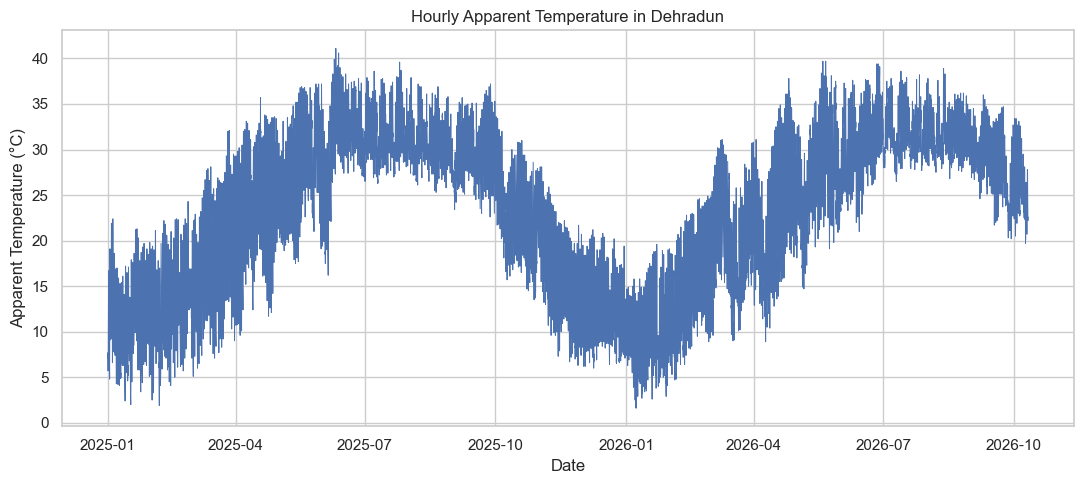

In [5]:
plt.figure(figsize=(11, 5))

plt.plot(df["time"], df["apparent_temperature"], linewidth=0.7)

plt.title("Hourly Apparent Temperature in Dehradun")
plt.xlabel("Date")
plt.ylabel("Apparent Temperature (°C)")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "apparent_temperature_trend.png", dpi=300)
plt.show()

4. Feature Engineering

Feature engineering is the process of creating useful input variables
for a machine learning model.

In this project, previous weather observations are used to create
lag features and rolling averages. These features help the model
understand recent weather patterns.

In [6]:
df = df.sort_values("time").drop_duplicates(subset="time").copy()
df = df.set_index("time")

weather_columns = [
    "temperature_2m",
    "relative_humidity_2m",
    "apparent_temperature",
    "precipitation",
    "wind_speed_10m",
    "cloud_cover",
    "shortwave_radiation"
]

# Create features using previous observations only
features = pd.DataFrame(index=df.index)

for col in weather_columns:
    for lag in [1, 3, 6, 12, 24]:
        features[f"{col}_lag_{lag}"] = df[col].shift(lag)

    for window in [6, 12, 24]:
        features[f"{col}_rolling_mean_{window}"] = (
            df[col].shift(1).rolling(window).mean()
        )

features["hour"] = df.index.hour
features["month"] = df.index.month

# Maximum apparent temperature in the next six hours
future_values = pd.concat(
    [df["apparent_temperature"].shift(-i) for i in range(1, 7)],
    axis=1
)

target_temperature = future_values.max(axis=1)

dataset = features.copy()
dataset["future_max_apparent_temperature"] = target_temperature

dataset = dataset.dropna()

print("Feature engineering completed.")
print("New dataset shape:", dataset.shape)

display(dataset.head())

Feature engineering completed.
New dataset shape: (15527, 59)


,temperature_2m_lag_1,temperature_2m_lag_3,temperature_2m_lag_6,temperature_2m_lag_12,temperature_2m_lag_24,temperature_2m_rolling_mean_6,temperature_2m_rolling_mean_12,temperature_2m_rolling_mean_24,relative_humidity_2m_lag_1,relative_humidity_2m_lag_3,relative_humidity_2m_lag_6,relative_humidity_2m_lag_12,relative_humidity_2m_lag_24,relative_humidity_2m_rolling_mean_6,relative_humidity_2m_rolling_mean_12,relative_humidity_2m_rolling_mean_24,apparent_temperature_lag_1,apparent_temperature_lag_3,apparent_temperature_lag_6,apparent_temperature_lag_12,apparent_temperature_lag_24,apparent_temperature_rolling_mean_6,apparent_temperature_rolling_mean_12,apparent_temperature_rolling_mean_24,precipitation_lag_1,precipitation_lag_3,precipitation_lag_6,precipitation_lag_12,precipitation_lag_24,precipitation_rolling_mean_6,precipitation_rolling_mean_12,precipitation_rolling_mean_24,wind_speed_10m_lag_1,wind_speed_10m_lag_3,wind_speed_10m_lag_6,wind_speed_10m_lag_12,wind_speed_10m_lag_24,wind_speed_10m_rolling_mean_6,wind_speed_10m_rolling_mean_12,wind_speed_10m_rolling_mean_24,cloud_cover_lag_1,cloud_cover_lag_3,cloud_cover_lag_6,cloud_cover_lag_12,cloud_cover_lag_24,cloud_cover_rolling_mean_6,cloud_cover_rolling_mean_12,cloud_cover_rolling_mean_24,shortwave_radiation_lag_1,shortwave_radiation_lag_3,shortwave_radiation_lag_6,shortwave_radiation_lag_12,shortwave_radiation_lag_24,shortwave_radiation_rolling_mean_6,shortwave_radiation_rolling_mean_12,shortwave_radiation_rolling_mean_24,hour,month,future_max_apparent_temperature
time,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-01-02 00:00:00,8.8,7.3,8.6,15.9,8.4,7.883333,11.608333,10.558333,86.0,97.0,97.0,69.0,97.0,95.166667,84.583333,85.333333,7.5,6.1,7.6,15.4,7.7,6.783333,10.883333,9.600000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.8,3.0,3.2,4.0,1.5,2.450000,3.100000,3.154167,21.0,18.0,11.0,11.0,100.0,19.666667,18.916667,44.666667,0.0,0.0,0.0,554.0,0.0,0.0,178.750000,133.666667,0,1,9.1
2025-01-02 01:00:00,9.8,8.0,7.7,16.6,8.5,8.083333,11.100000,10.616667,77.0,93.0,99.0,69.0,96.0,91.833333,85.250000,84.500000,8.3,6.8,6.9,16.4,7.5,6.900000,10.291667,9.625000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,3.2,0.5,3.2,2.7,2.416667,3.016667,3.216667,18.0,26.0,17.0,14.0,97.0,20.833333,19.500000,41.250000,0.0,0.0,0.0,543.0,0.0,0.0,132.583333,133.666667,1,1,9.1
2025-01-02 02:00:00,10.7,8.8,6.9,17.0,8.5,8.583333,10.608333,10.708333,67.0,86.0,99.0,69.0,91.0,86.500000,85.083333,83.291667,9.0,7.5,5.8,16.7,7.2,7.250000,9.675000,9.687500,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.8,2.8,2.0,4.2,3.3,2.800000,2.983333,3.220833,49.0,21.0,25.0,12.0,84.0,26.166667,22.416667,39.250000,0.0,0.0,0.0,471.0,0.0,0.0,87.333333,133.666667,2,1,7.9
2025-01-02 03:00:00,11.2,9.8,7.3,16.3,9.0,9.300000,10.125000,10.820833,59.0,77.0,97.0,72.0,80.0,79.833333,84.250000,81.958333,9.1,8.3,6.1,16.0,7.4,7.800000,9.041667,9.766667,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.5,3.0,3.0,4.8,3.9,3.050000,2.925000,3.229167,5.0,18.0,18.0,21.0,78.0,22.833333,21.833333,35.958333,0.0,0.0,0.0,347.0,0.0,0.0,48.083333,133.666667,3,1,11.3
2025-01-02 04:00:00,10.6,10.7,8.0,14.7,8.2,9.850000,9.650000,10.887500,54.0,67.0,93.0,76.0,79.0,72.666667,82.750000,80.875000,7.8,9.0,6.8,14.3,6.4,8.083333,8.358333,9.783333,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.8,2.8,3.2,4.4,2.9,3.516667,3.008333,3.308333,67.0,49.0,26.0,26.0,54.0,31.000000,25.666667,35.500000,0.0,0.0,0.0,188.0,0.0,0.0,19.166667,133.666667,4,1,13.3


In [7]:
split_index = int(len(dataset) * 0.80)

train_data = dataset.iloc[:split_index].copy()
test_data = dataset.iloc[split_index:].copy()

threshold = train_data[
    "future_max_apparent_temperature"
].quantile(0.90)

train_data["high_temperature"] = (
    train_data["future_max_apparent_temperature"] > threshold
).astype(int)

test_data["high_temperature"] = (
    test_data["future_max_apparent_temperature"] > threshold
).astype(int)

print("High-temperature threshold:", round(threshold, 2), "°C")
print("\nTraining records:", len(train_data))
print("Testing records:", len(test_data))

print("\nTraining target distribution:")
display(train_data["high_temperature"].value_counts())

High-temperature threshold: 34.3 °C

Training records: 12421
Testing records: 3106

Training target distribution:


high_temperature
0    11179
1     1242
Name: count, dtype: int64

In [8]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

X_train = train_data.drop(
    columns=["future_max_apparent_temperature", "high_temperature"]
)

X_test = test_data.drop(
    columns=["future_max_apparent_temperature", "high_temperature"]
)

y_train = train_data["high_temperature"]
y_test = test_data["high_temperature"]

# Remove the final six training rows to avoid crossing the split boundary
X_train = X_train.iloc[:-6]
y_train = y_train.iloc[:-6]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (12415, 58)
X_test: (3106, 58)
y_train: (12415,)
y_test: (3106,)


In [10]:
from sklearn.impute import SimpleImputer

# Calculate threshold without the six boundary observations
threshold = train_data[
    "future_max_apparent_temperature"
].iloc[:-6].quantile(0.90)

train_data["high_temperature"] = (
    train_data["future_max_apparent_temperature"] > threshold
).astype(int)

test_data["high_temperature"] = (
    test_data["future_max_apparent_temperature"] > threshold
).astype(int)

X_train = train_data.drop(
    columns=["future_max_apparent_temperature", "high_temperature"]
).iloc[:-6]

X_test = test_data.drop(
    columns=["future_max_apparent_temperature", "high_temperature"]
)

y_train = train_data["high_temperature"].iloc[:-6]
y_test = test_data["high_temperature"]

print("Threshold:", round(threshold, 2), "°C")
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Threshold: 34.3 °C
Training shape: (12415, 58)
Testing shape: (3106, 58)

Training target distribution:
high_temperature
0    11179
1     1236
Name: count, dtype: int64

Testing target distribution:
high_temperature
0    2288
1     818
Name: count, dtype: int64


5. Machine Learning Model Building

Three classification algorithms are used in this project:
1. Logistic Regression
2. Decision Tree
3. Random Forest

A baseline model is also included for comparison.

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),

    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(
            max_depth=6,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=200,
            max_depth=10,
            class_weight="balanced",
            random_state=42
        ))
    ])
}

print("Models are ready.")

Models are ready.


In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

results = []
trained_models = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(
    results_df.round(3).sort_values(
        by="F1 Score", ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1 Score
3,Random Forest,0.854,0.657,0.934,0.771
1,Logistic Regression,0.808,0.581,0.974,0.728
2,Decision Tree,0.772,0.538,0.952,0.687
0,Baseline,0.737,0.000,0.000,0.000


<Figure size 1000x500 with 0 Axes>

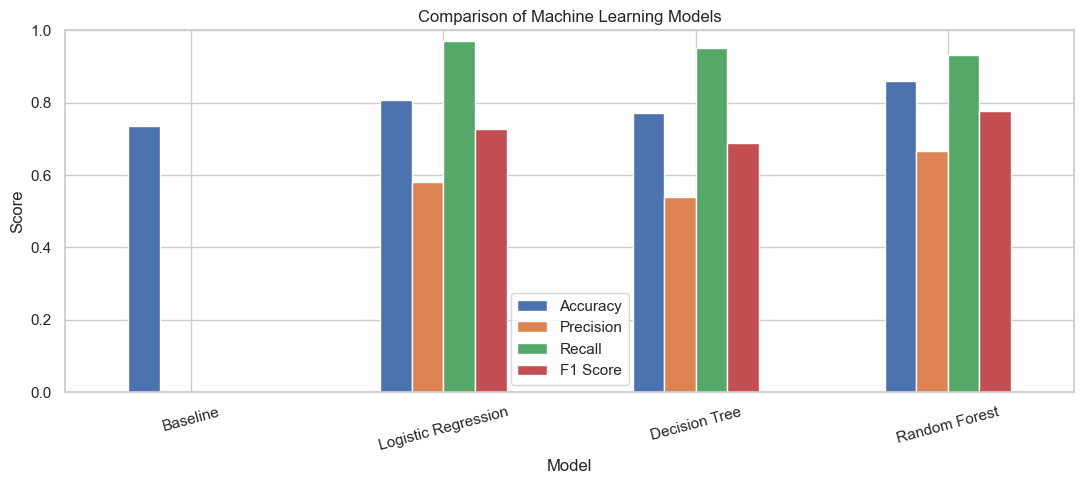

In [22]:
plt.figure(figsize=(10, 5))

results_plot = results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
]

results_plot.plot(kind="bar", figsize=(11, 5))

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "model_comparison.png",
    dpi=300
)

plt.show()

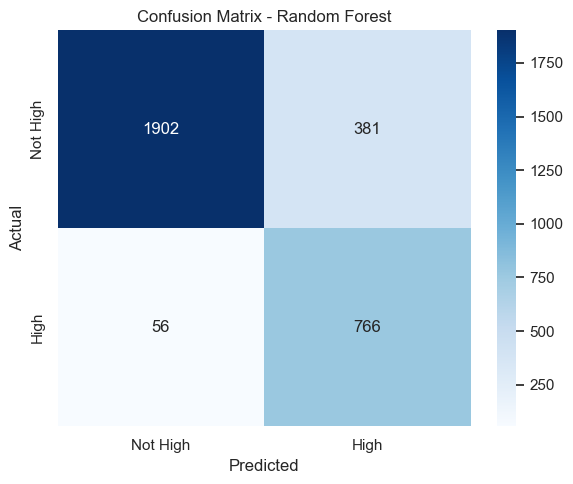

Best model based on F1 Score: Random Forest


In [23]:
best_model_name = (
    results_df.sort_values("F1 Score", ascending=False)
    .iloc[0]["Model"]
)

best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not High", "High"],
    yticklabels=["Not High", "High"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "confusion_matrix.png",
    dpi=300
)

plt.show()

print("Best model based on F1 Score:", best_model_name)

In [15]:
print("Classification Report:", best_model_name)

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=["Not High", "High"],
        zero_division=0
    )
)

Classification Report: Random Forest
              precision    recall  f1-score   support

    Not High       0.97      0.83      0.89      2288
        High       0.66      0.93      0.77       818

    accuracy                           0.85      3106
   macro avg       0.81      0.88      0.83      3106
weighted avg       0.89      0.85      0.86      3106



In [16]:
results_df.to_csv(
    OUTPUT_DIR / "model_results.csv",
    index=False
)

print("Results saved successfully.")
print("Output folder:", OUTPUT_DIR.resolve())

Results saved successfully.
Output folder: C:\Users\Ravi\OneDrive\FDS LAB\Heatlens-Dehradun\outputs


 6. Final Data Validation

Before model evaluation, incomplete future prediction windows are
removed. Each target must contain six complete future hourly values.

In [19]:
# Ensure that the data has a complete hourly time index
df_hourly = df[weather_columns].sort_index().asfreq("h")

expected_hours = pd.date_range(
    start=df_hourly.index.min(),
    end=df_hourly.index.max(),
    freq="h"
)

missing_hours = len(expected_hours.difference(df_hourly.index))

print("Missing hourly timestamps:", missing_hours)

# Rebuild lag and rolling features
features = pd.DataFrame(index=df_hourly.index)

for col in weather_columns:
    for lag in [1, 3, 6, 12, 24]:
        features[f"{col}_lag_{lag}"] = df_hourly[col].shift(lag)

    for window in [6, 12, 24]:
        features[f"{col}_rolling_mean_{window}"] = (
            df_hourly[col].shift(1).rolling(window).mean()
        )

features["hour"] = features.index.hour
features["month"] = features.index.month

# Calculate the following six complete hourly values
future_values = pd.concat(
    [
        df_hourly["apparent_temperature"].shift(-i)
        for i in range(1, 7)
    ],
    axis=1
)

# Keep only rows with all six future values
complete_horizon = future_values.notna().all(axis=1)

target_temperature = future_values.max(axis=1)

dataset = features.copy()
dataset["future_max_apparent_temperature"] = target_temperature

dataset = dataset.loc[complete_horizon].dropna().copy()

print("\nFinal validated dataset shape:", dataset.shape)
print("First timestamp:", dataset.index.min())
print("Last timestamp:", dataset.index.max())

Missing hourly timestamps: 0

Final validated dataset shape: (15522, 59)
First timestamp: 2025-01-02 00:00:00
Last timestamp: 2026-10-10 17:00:00


In [20]:
split_index = int(len(dataset) * 0.80)

train_data = dataset.iloc[:split_index].copy()
test_data = dataset.iloc[split_index:].copy()

# Do not train on examples whose six-hour target enters the test period
test_start = test_data.index.min()

valid_train = (
    train_data.index + pd.Timedelta(hours=6)
) < test_start

train_data = train_data.loc[valid_train].copy()

# Calculate threshold using training data only
threshold = train_data[
    "future_max_apparent_temperature"
].quantile(0.90)

train_data["high_temperature"] = (
    train_data["future_max_apparent_temperature"] > threshold
).astype(int)

test_data["high_temperature"] = (
    test_data["future_max_apparent_temperature"] > threshold
).astype(int)

X_train = train_data.drop(
    columns=["future_max_apparent_temperature", "high_temperature"]
)

X_test = test_data.drop(
    columns=["future_max_apparent_temperature", "high_temperature"]
)

y_train = train_data["high_temperature"]
y_test = test_data["high_temperature"]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Threshold:", round(threshold, 2), "°C")

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training records: 12411
Testing records: 3105
Threshold: 34.3 °C

Training class distribution:
high_temperature
0    11178
1     1233
Name: count, dtype: int64

Testing class distribution:
high_temperature
0    2283
1     822
Name: count, dtype: int64


In [21]:
results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(
    results_df.round(3).sort_values(
        "F1 Score", ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1 Score
3,Random Forest,0.859,0.668,0.932,0.778
1,Logistic Regression,0.808,0.582,0.971,0.728
2,Decision Tree,0.771,0.539,0.953,0.688
0,Baseline,0.735,0.000,0.000,0.000


In [25]:
# Save the final model comparison
results_df.to_csv(
    OUTPUT_DIR / "final_model_comparison.csv",
    index=False
)

# Save the final confusion matrix
final_cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=[0, 1]
)

pd.DataFrame(
    final_cm,
    index=["Actual Not High", "Actual High"],
    columns=["Predicted Not High", "Predicted High"]
).to_csv(OUTPUT_DIR / "final_confusion_matrix.csv")

# Save dataset information
project_summary = {
    "Dataset rows": len(dataset),
    "Dataset columns": dataset.shape[1],
    "Training records": len(X_train),
    "Testing records": len(X_test),
    "Training start": str(X_train.index.min()),
    "Training end": str(X_train.index.max()),
    "Testing start": str(X_test.index.min()),
    "Testing end": str(X_test.index.max()),
    "High temperature threshold": threshold,
    "Best model": best_model_name
}

pd.Series(project_summary).to_csv(
    OUTPUT_DIR / "project_summary.csv",
    header=["Value"]
)

print("Final project results saved successfully.")
display(results_df.round(4))
display(pd.Series(project_summary))

Final project results saved successfully.


,Model,Accuracy,Precision,Recall,F1 Score
0,Baseline,0.7353,0.0000,0.0000,0.0000
1,Logistic Regression,0.8077,0.5821,0.9708,0.7278
2,Decision Tree,0.7713,0.5385,0.9526,0.6880
3,Random Forest,0.8593,0.6678,0.9319,0.7781


Dataset rows                                15522
Dataset columns                                59
Training records                            12411
Testing records                              3105
Training start                2025-01-02 00:00:00
Training end                  2026-06-03 02:00:00
Testing start                 2026-06-03 09:00:00
Testing end                   2026-10-10 17:00:00
High temperature threshold                   34.3
Best model                          Random Forest
dtype: object

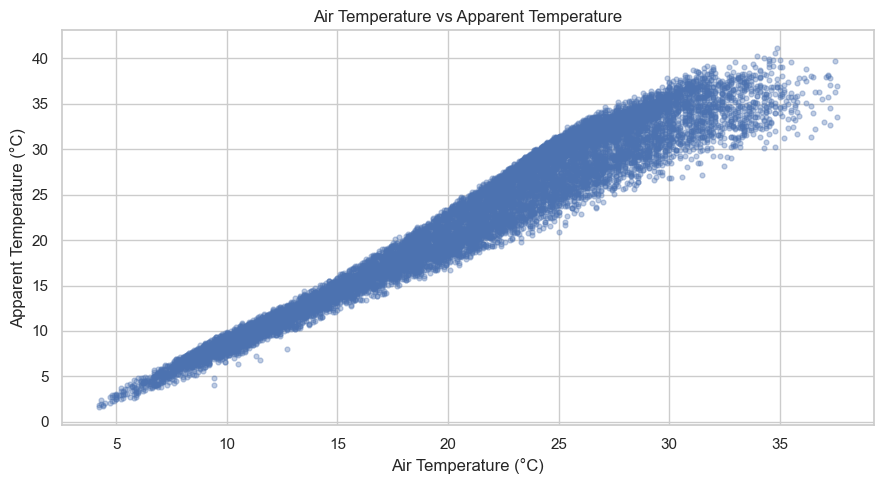

In [26]:
# Scatter plot: Temperature vs Apparent Temperature

plt.figure(figsize=(9, 5))

plt.scatter(
    df["temperature_2m"],
    df["apparent_temperature"],
    alpha=0.35,
    s=12
)

plt.title("Air Temperature vs Apparent Temperature")
plt.xlabel("Air Temperature (°C)")
plt.ylabel("Apparent Temperature (°C)")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "temperature_scatter_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

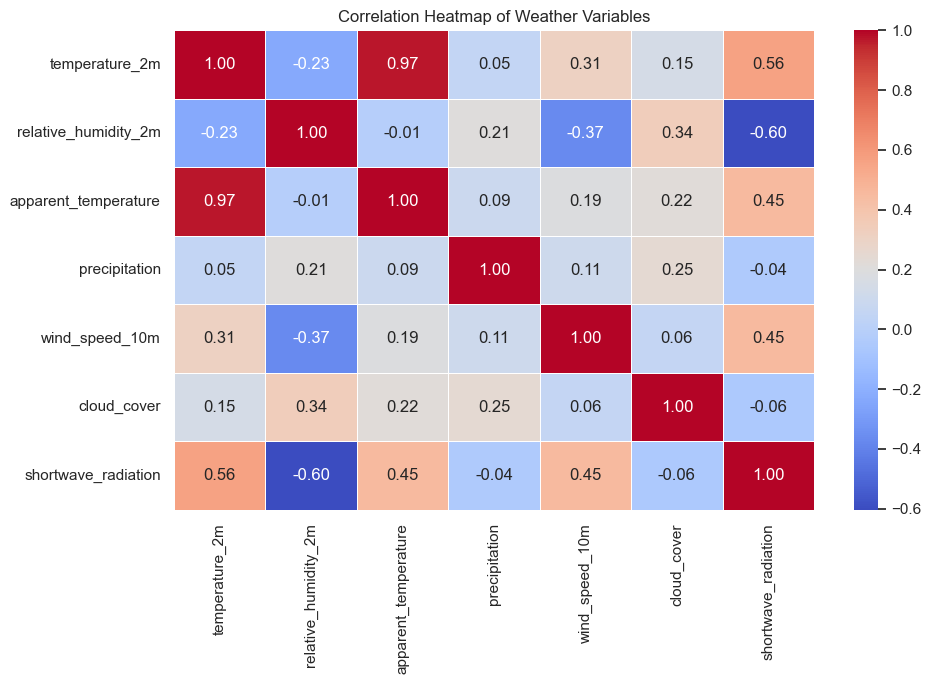

In [27]:
# Correlation heatmap of weather variables

correlation_columns = [
    "temperature_2m",
    "relative_humidity_2m",
    "apparent_temperature",
    "precipitation",
    "wind_speed_10m",
    "cloud_cover",
    "shortwave_radiation"
]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Weather Variables")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

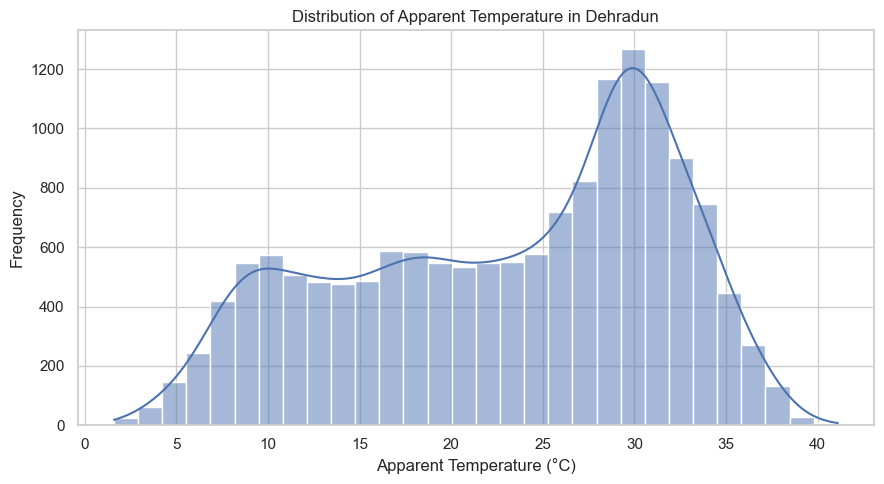

In [28]:
# Histogram of apparent temperature

plt.figure(figsize=(9, 5))

sns.histplot(
    df_hourly["apparent_temperature"].dropna(),
    bins=30,
    kde=True
)

plt.title("Distribution of Apparent Temperature in Dehradun")
plt.xlabel("Apparent Temperature (°C)")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "apparent_temperature_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

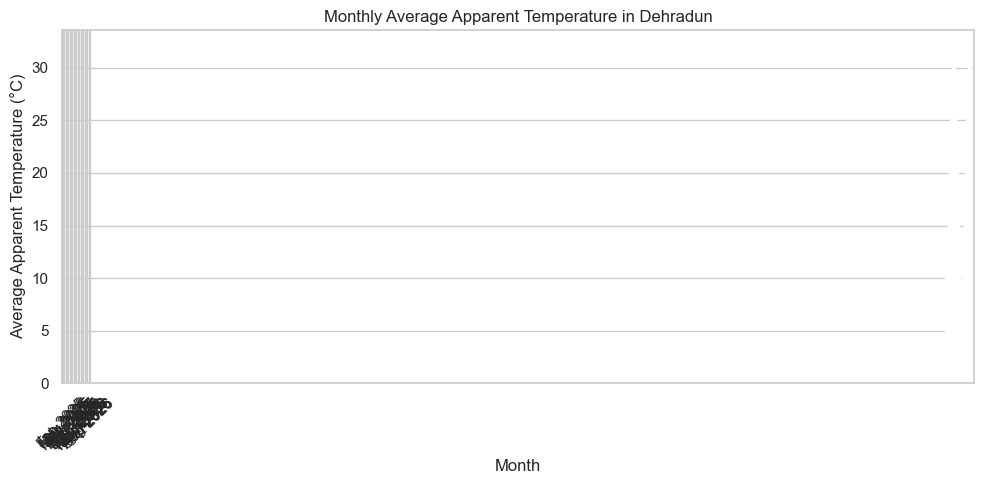

time
2025-01-31    11.17
2025-02-28    12.86
2025-03-31    17.20
2025-04-30    23.37
2025-05-31    27.72
2025-06-30    31.03
2025-07-31    31.61
2025-08-31    30.53
2025-09-30    29.43
2025-10-31    22.96
2025-11-30    15.70
2025-12-31    12.21
2026-01-31     9.63
2026-02-28    14.49
2026-03-31    19.84
2026-04-30    22.53
2026-05-31    26.95
2026-06-30    30.76
2026-07-31    31.98
2026-08-31    31.47
2026-09-30    28.44
2026-10-31    26.08
Freq: ME, Name: apparent_temperature, dtype: float64

In [29]:
# Monthly average apparent temperature

monthly_avg = (
    df_hourly["apparent_temperature"]
    .resample("ME")
    .mean()
    .dropna()
)

plt.figure(figsize=(10, 5))

monthly_avg.plot(kind="bar")

plt.title("Monthly Average Apparent Temperature in Dehradun")
plt.xlabel("Month")
plt.ylabel("Average Apparent Temperature (°C)")
plt.xticks(
    range(len(monthly_avg)),
    monthly_avg.index.strftime("%b %Y"),
    rotation=45
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "monthly_average_temperature.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(monthly_avg.round(2))